# 05. Feature Engineering

Construction des variables, transformations, encodages et creation du dataset train final pour la modelisation.

**Sortie principale :** `artifacts/05_feature_engineering/data/train_features_full.parquet`

In [1]:
# Importation des bibliothèques principales
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.functions import col, round as spark_round
from pyspark.sql.functions import avg

from pyspark.ml.stat import *
from pyspark.ml import Pipeline
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import  VectorAssembler , RobustScaler
from pyspark.ml.feature import StringIndexer, OneHotEncoder, StandardScaler
from pyspark.ml.classification import RandomForestClassifier,LogisticRegression,GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator ,MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

#  Visualisation et analyse complémentaire
import json
from pprint import pprint
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from builtins import round

from pyspark.sql.functions import count, col, when, sum as spark_sum


In [2]:
from pathlib import Path
import sys
import mlflow

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"

ARTIFACTS_ROOT = PROJECT_DIR / "artifacts"
MODELS_ROOT = PROJECT_DIR / "models"
MLFLOW_DIR = PROJECT_DIR / "Mlflow"
MLFLOW_ARTIFACTS_DIR = MLFLOW_DIR / "artifacts"
SRC_DIR = PROJECT_DIR / "src"
INPUT_STAGE_DIR = ARTIFACTS_ROOT / "03_quality_cleaning" / "data"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

MLFLOW_DIR.mkdir(parents=True, exist_ok=True)
MLFLOW_ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

STAGE_NAME = "05_feature_engineering"
STAGE_ARTIFACTS_DIR = ARTIFACTS_ROOT / STAGE_NAME
STAGE_DATA_DIR = STAGE_ARTIFACTS_DIR / "data"
GROUP_STATS_DIR = STAGE_ARTIFACTS_DIR / "group_stats"
FN_RECOVERY_DIR = STAGE_ARTIFACTS_DIR / "fn_recovery"
SCALING_DIR = STAGE_ARTIFACTS_DIR / "scaling"
ENCODING_DIR = STAGE_ARTIFACTS_DIR / "encoding"
FREQUENCY_ENCODING_DIR = ENCODING_DIR / "frequency_encoding"
TARGET_ENCODING_DIR = ENCODING_DIR / "target_encoding"
FEATURES_DIR = STAGE_ARTIFACTS_DIR / "features"
METADATA_DIR = STAGE_ARTIFACTS_DIR / "metadata"
METRICS_DIR = STAGE_ARTIFACTS_DIR / "metrics"
PLOTS_DIR = STAGE_ARTIFACTS_DIR / "plots"

for _dir in (
    ARTIFACTS_ROOT,
    MODELS_ROOT,
    STAGE_ARTIFACTS_DIR,
    STAGE_DATA_DIR,
    GROUP_STATS_DIR,
    FN_RECOVERY_DIR,
    SCALING_DIR,
    ENCODING_DIR,
    FREQUENCY_ENCODING_DIR,
    TARGET_ENCODING_DIR,
    FEATURES_DIR,
    METADATA_DIR,
    METRICS_DIR,
    PLOTS_DIR,
):
    _dir.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{(MLFLOW_DIR / 'mlflow.db').resolve().as_posix()}")

EXPERIMENT_NAME = "fraud_detection_ieee"
ARTIFACT_LOCATION = (MLFLOW_ARTIFACTS_DIR / EXPERIMENT_NAME).resolve().as_uri()

experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    experiment_id = mlflow.create_experiment(
        EXPERIMENT_NAME,
        artifact_location=ARTIFACT_LOCATION
    )
else:
    experiment_id = experiment.experiment_id

experiment = mlflow.get_experiment(experiment_id)

assert experiment.artifact_location == ARTIFACT_LOCATION, (
    f"Mauvais artifact_location: {experiment.artifact_location}")

mlflow.set_experiment(EXPERIMENT_NAME)
print(experiment)

<Experiment: artifact_location='file:///C:/Users/El-fahad%20COMBO/Desktop/Fraud_Detection_IEEE/Mlflow/artifacts/fraud_detection_ieee', creation_time=1782163499721, experiment_id='53', last_update_time=1782163499721, lifecycle_stage='active', name='fraud_detection_ieee', tags={}, workspace='default'>


In [ ]:
# Création de la session Spark

spark = SparkSession.builder \
    .appName("DetectionFraude") \
    .master("local[8]") \
    .config("spark.driver.memory", "10g") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate() 

# Affichage de la session pour vérification

spark 

In [4]:
# fonciton nettoyage de mémoire 
def cleanup(*vars_to_del):
    for var in vars_to_del:
        del var
    import gc; gc.collect()
    spark.catalog.clearCache()

In [5]:
from fraud_pipeline import (
    LOG_FEATURE_COLUMNS,
    VARS_TO_ENCODE,
    VARS_TO_FREQUENCY_ENCODE,
    VARS_TO_TARGET_ENCODE,
    add_baseline_features,
    add_class_weight,
    add_class_weight_with_train_ratio,
    add_temporal_features,
    add_log_features,
    add_m789_combo,
    add_post_model_features,
    add_recent_intense_feature,
    add_uid_full,
    add_uid_simple,
    assemble_train_valid_features,
    dataframe_profile,
    fit_and_apply_encoding_train_valid,
    fit_and_apply_frequency_train_valid,
    fit_and_apply_fn_recovery_train_valid,
    fit_and_apply_group_aggregations_train_valid,
    fit_and_apply_scaler_train_valid,
    fit_and_apply_target_train_valid,
    get_baseline_feature_columns,
    save_json,)

mlflow.end_run()
mlflow.start_run(run_name=STAGE_NAME)
mlflow.set_tag("stage", STAGE_NAME)

mlflow.set_tag("notebook", "05_feature_engineering.ipynb")
df = spark.read.parquet((INPUT_STAGE_DIR / "02_train_clean.parquet").as_posix())


# 6. Feature Engineering

####  Objectif : Créer des variables explicatives pertinentes pour améliorer la détection de fraude

Cette étape consiste à **enrichir et transformer le dataset** afin de renforcer la performance du futur modèle.  
L'objectif est double :

1. **Maximiser la puissance prédictive** des données,
2. **Stabiliser, simplifier et structurer** les variables pour faciliter l’apprentissage machine.

---

Nous allons structurer cette phase en **trois sous-étapes complémentaires** :

1. **Feature Construction**  
   Création de nouvelles variables à partir de la logique métier et des patterns identifiés lors de l’EDA :
   - Flags : `is_high_amount`, `is_recent_activity`, `is_weekend`, `is_credit_card`, etc.
   - Combinaisons : `card4_card6`
   - Présence de données : `has_identity`, `has_X`
   - Ratios comportementaux : `C1_sur_D1`

2. **Transformation, Scaling & Encodage**  
  Préparation des données numériques et catégorielles :   
   - **Log-transform** des variables asymétriques (`TransactionAmt`, `D1`, etc.)
   - **StandardScaler** après log-transform sur les variables continues
   - **Encodage** des variables catégorielles (`StringIndexer` + `OneHotEncoder`)

3. **Finalisation du dataset**  
   - Assemblage final des features (VectorAssembler)
   - Nettoyage et suppression des colonnes redondantes
   - Préparation du jeu de test avant modélisation



## 6.1 Feature Construction

####  Objectif : Enrichir le dataset avec des indicateurs binaires et dérivés simples

Cette étape vise à ajouter des variables dérivées directement issues de l’intuition métier et de l’analyse exploratoire.  
Ces features permettent de capturer des comportements spécifiques sans complexité excessive.

####  Features déjà présentes (issues des étapes précédentes) :
- `has_identity` : identifie les transactions enrichies via le fichier d’identité (créée lors de l’EDA brut)
- `has_X` : série de variables binaires (créées au nettoyage) capturant la présence d’information dans des colonnes incomplètes (`has_D12`, `has_V138`, etc.)

####  Nouvelles features ajoutées ici :

- `is_recent_activity` : identifie des comptes ou comportements très récents (`D1 == 0`)
- `is_high_amount` : détecte les montants de transaction très élevés (`TransactionAmt > 1000`)
- `is_product_C` : flag pour le produit le plus frauduleux (`ProductCD == "C"`)
- `is_credit_card` : type de carte utilisé (`card6 == "credit"`)
- `is_discover_card` : réseau de carte à haut risque (`card4 == "discover"`)
- `card4_card6` : combinaison des deux types de carte
- `day`, `is_weekend` : dérivées temporelles à partir de `TransactionDT`

In [6]:
df = add_baseline_features(df)


###   Analyse des variables binaires construites

Nous analysons ici les variables binaires créées , l’objectif est d’évaluer leur **pouvoir discriminant** à travers deux axes :

- **Le taux de fraude** associé à la valeur 1,
- **La fréquence d’apparition** de cette modalité dans le dataset.

Nous utilisons un échantillon aléatoire pour alléger le traitement et visualiser les tendances globales.

In [7]:
def plot_fraud_vs_freq(df, vars_binaires, sample_frac=0.05):
    
    df_sample = df.select(vars_binaires + ["isFraud"]).sample(fraction=sample_frac).toPandas()

    # calculs taux de fraude et fréquence
    data = []
    for var in vars_binaires:
        if var in df_sample.columns:
            subset = df_sample[df_sample[var] == 1]
            if len(subset) > 0:
                data.append({
                    "variable": var,
                    "taux_fraude": subset["isFraud"].mean() * 100,
                    "frequence": df_sample[var].mean() * 100
                })

    df_plot = pd.DataFrame(data).sort_values("taux_fraude", ascending=False)

    fig, ax1 = plt.subplots(figsize=(7, 5))
    sns.barplot(data=df_plot, y="variable", x="taux_fraude", color="salmon", ax=ax1)
    ax1.set_xlabel("Taux de fraude (%)")
    ax1.set_ylabel("Variable")

    ax2 = ax1.twiny()
    ax2.plot(df_plot["frequence"], df_plot["variable"], "o-", color="steelblue", label="Fréquence (%)")
    ax2.set_xlim(0, df_plot["frequence"].max() * 1.2)
    ax2.set_xlabel("Fréquence (%)")
    ax2.legend(loc="lower right")

    plt.title("Taux de fraude vs fréquence des variables binaires")
    plt.tight_layout()
    plt.show()

    cleanup(df_sample, df_plot)


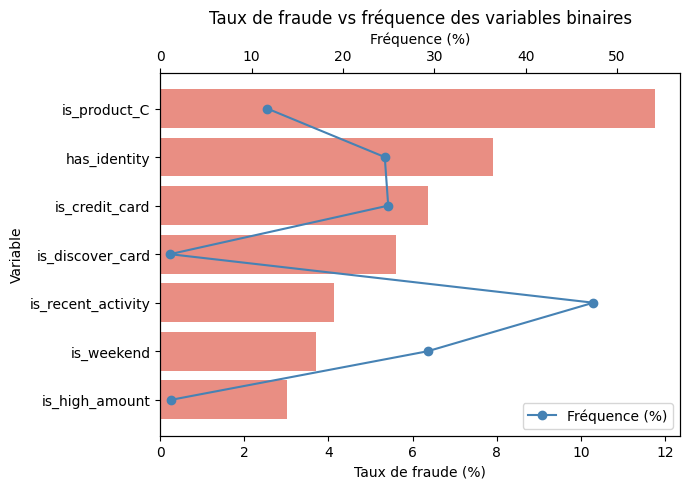

In [8]:
vars_bin = ["is_recent_activity", "is_product_C", "is_high_amount", "is_discover_card", "is_credit_card",
            "has_identity", "is_weekend"]

plot_fraud_vs_freq(df, vars_bin)


### Analyse exploratoire de la variable catégorielle `card4_card6`

La variable `card4_card6` est une **combinaison de deux colonnes catégorielles** (`card4` et `card6`) représentant respectivement :
- Le **réseau de carte bancaire** (`visa`, `mastercard`, `discover`, etc.)
- Le **type de carte** (`credit`, `debit`, `charge card`, etc.)

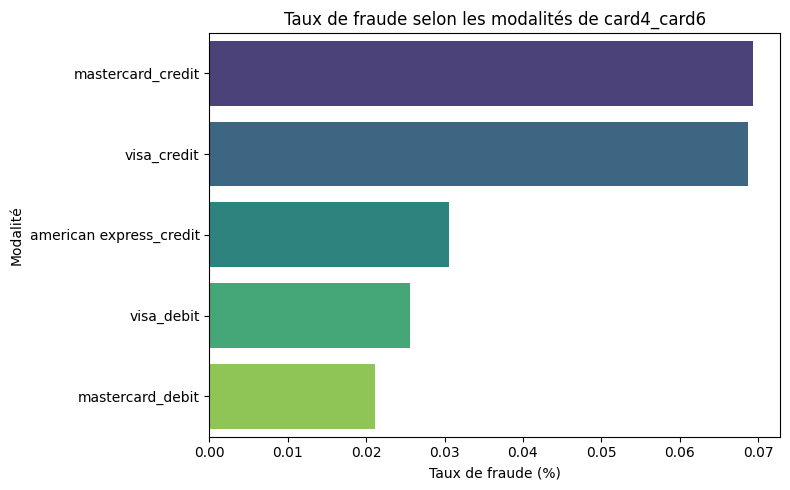

In [9]:
df_sample = df.select("card4_card6", "isFraud").dropna().sample(fraction=0.05).toPandas()

# taux de fraude + fréquence
stats = df_sample.groupby("card4_card6")["isFraud"].agg(["mean", "count"]).reset_index()
stats.columns = ["card4_card6", "taux_fraude", "frequence"]

# Filtrage fréquence (>= 1%)
stats["frequence_pct"] = stats["frequence"] / stats["frequence"].sum()
stats_filtrées = stats[stats["frequence_pct"] >= 0.01].sort_values("taux_fraude", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=stats_filtrées, y="card4_card6", x="taux_fraude",hue="card4_card6" ,palette="viridis")
plt.title("Taux de fraude selon les modalités de card4_card6")
plt.xlabel("Taux de fraude (%)")
plt.ylabel("Modalité")
plt.tight_layout()
plt.show()
cleanup(df_sample, stats, stats_filtrées)   

####  Interprétation – `card4_card6`

`card4_card6` combine le type (`card6`) et le réseau de carte (`card4`).  
L’analyse montre que certaines modalités comme `visa_credit` et `mastercard_credit` présentent des **taux de fraude élevés** (> 7 % et ~6.5 %).

En revanche, des combinaisons comme `mastercard_debit` sont **plus fréquentes mais moins risquées** (~2 %).

Ces différences justifient la conservation de cette variable, qui sera **encodée (StringIndexer + OneHotEncoder)**. Les modalités rares seront regroupées ou exclues si nécessaire.


## 6.2 Transformation, Scaling & Encodage

####  Objectif : Adapter les variables existantes pour les rendre compatibles avec les algorithmes de machine learning

Cette étape vise à :
- **Stabiliser** les distributions asymétriques via des transformations log (`log1p`)
- **Uniformiser les échelles** des variables continues grâce au **scaling**
- **Encoder** efficacement les variables catégorielles avec `OneHotEncoding`

###  Log-transformations & feature combinée

On applique une transformation logarithmique `log1p(x)` sur les variables fortement asymétriques pour :
- Réduire l’effet des valeurs extrêmes
- Rendre les distributions plus symétriques

In [10]:
cols_log = LOG_FEATURE_COLUMNS
df = add_log_features(df, cols_log=cols_log)


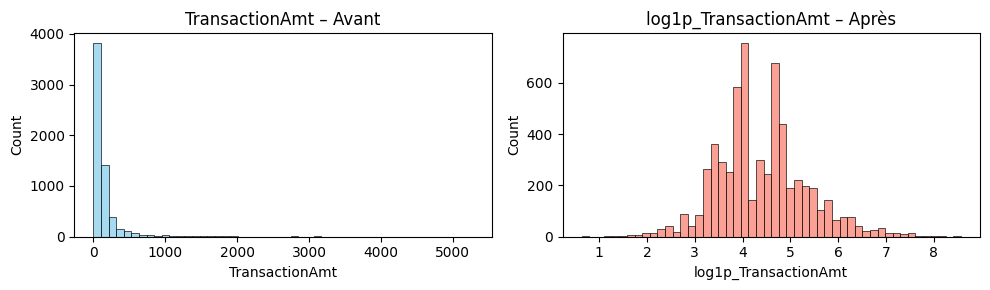

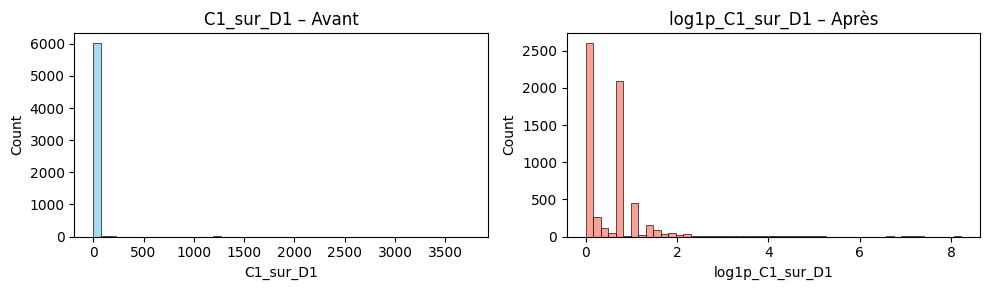

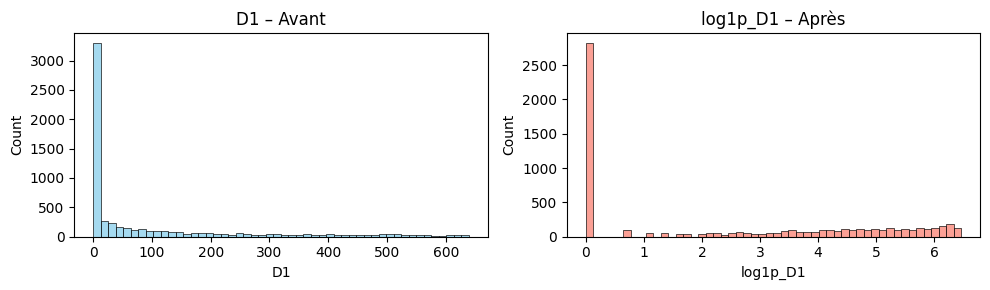

In [11]:
df_sample = df.select(["TransactionAmt", "log1p_TransactionAmt",
                       "C1_sur_D1", "log1p_C1_sur_D1",
                       "D1", "log1p_D1"]).sample(fraction=0.01).toPandas()

# Colonnes à comparer
features = [("TransactionAmt", "log1p_TransactionAmt"),
            ("C1_sur_D1", "log1p_C1_sur_D1"),
            ("D1", "log1p_D1")]

for orig, loged in features:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(df_sample[orig], bins=50, ax=axes[0], kde=False, color="skyblue")
    axes[0].set_title(f"{orig} – Avant")

    sns.histplot(df_sample[loged], bins=50, ax=axes[1], kde=False, color="salmon")
    axes[1].set_title(f"{loged} – Après")

    plt.tight_layout()
    plt.show()

cleanup(df_sample)


In [12]:
df = add_post_model_features(df)


#### Hypothèse métier – 

Malgré la transformation `log1p`, la variable `C1_sur_D1` reste très concentrée sur les faibles valeurs, ce qui reflète bien la nature de la fraude :  
les fraudeurs agissent souvent de manière **très intense sur un laps de temps très court**.

Or, nous disposons déjà de la variable binaire `is_recent_activity`, qui capte le fait que `D1 == 0`, soit **une activité récente ou immédiate**.


#### l'Idée : combiner ces deux informations

Nous disposons déjà de :

- `is_recent_activity` : indique si l'activité est immédiate (`D1 == 0`)
- `log1p_C1_sur_D1` : mesure l’intensité du comportement

 Nous combinons ces deux informations dans une **nouvelle variable binaire** `is_recent_intense` :


In [13]:
df = add_recent_intense_feature(df, threshold=2.5)

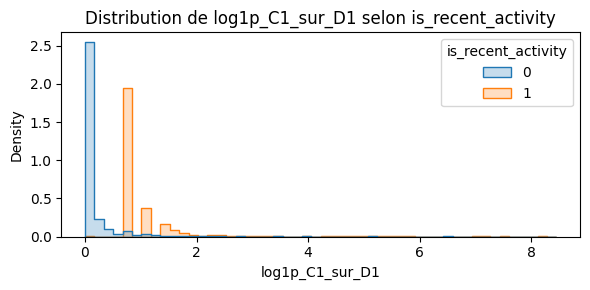

In [14]:
df_sample = df.select("log1p_C1_sur_D1", "is_recent_activity").sample(fraction=0.01).toPandas()

plt.figure(figsize=(6, 3))
sns.histplot(data=df_sample, x="log1p_C1_sur_D1", hue="is_recent_activity", bins=50, element="step", stat="density")
plt.title("Distribution de log1p_C1_sur_D1 selon is_recent_activity")
plt.xlabel("log1p_C1_sur_D1")
plt.tight_layout()
plt.show()

cleanup(df_sample)

In [15]:
df.groupBy("is_recent_intense").agg(
    count("*").alias("n_obs"),
    spark_round(mean("isFraud") * 100, 2).alias("taux_fraude_%")
).orderBy("is_recent_intense").show()


+-----------------+------+-------------+
|is_recent_intense| n_obs|taux_fraude_%|
+-----------------+------+-------------+
|                0|581580|          3.2|
|                1|  8960|         23.2|
+-----------------+------+-------------+



In [16]:
if "is_night_transaction" not in df.columns:
    df = add_temporal_features(df)

night_rows = []
for flag_value in [0, 1]:
    row = (
        df.filter(col("is_night_transaction") == flag_value)
        .agg(count("*").alias("count"), avg("isFraud").alias("fraud_rate"))
        .first()
    )
    night_rows.append({
        "is_night_transaction": flag_value,
        "count_flag": row["count"],
        "fraud_rate_pct": round(row["fraud_rate"] * 100, 2) if row["fraud_rate"] is not None else 0,
    })

night_summary_df = pd.DataFrame(night_rows)
display(night_summary_df)


,is_night_transaction,count_flag,fraud_rate_pct
0,0,366786,3.37
1,1,223754,3.70


#### Interprétation – `is_recent_intense` vs `isFraud`

Le taux de fraude observé est :

- **23,20 %** lorsque `is_recent_intense = 1` ;
- **3,20 %** lorsque `is_recent_intense = 0`.

Cette différence descriptive indique que la combinaison d’une valeur faible de `D1` et d’un ratio `C1_sur_D1` élevé est associée à un risque de fraude plus important.

De plus, l'analyse sur la période de la journée révèle :
- Les **heures de jours (is_night_transaction = 0)** ont un taux de fraude de **3.37%**.
- Les **heures de nuit (is_night_transaction = 1)** ont un taux de fraude très réhaussé à **3.70%**, montrant une légère préférence pour les horaires de nuit.

Conclusion :
- `is_recent_intense` est un **signal comportemental fort**, capturant des fraudes rapides et intenses
- Elle sera **conservée pour la modélisation**, et priorisée dans les sélections de features

###   Analyse des nouvelles variables temporelles et profils récurrents

On analyse ici les variables ajoutées en plus des flags classiques :
- `TransactionHour` : heure de la transaction (0-23) - une fraude nocturne se comporte-t-elle différemment ?
- `log1p_recent_intense_score` : version continue du flag `is_recent_intense`
- `uid_simple` / `uid_full` : variables d'identités strictes pour détecter les acheteurs récurrents (freq-encoded ensuite)

Dans ce bloc on exécute également l'ajout des variables temporelles :


,TransactionHour,count,fraud_rate_pct
0,0,37795,3.137981
1,1,32797,3.131384
2,2,26732,3.748317
3,3,20802,3.831362
4,4,14839,5.189029
5,5,9701,7.030203
6,6,6007,7.774263
7,7,3704,10.610151
8,8,2591,9.301428
9,9,2479,8.995563


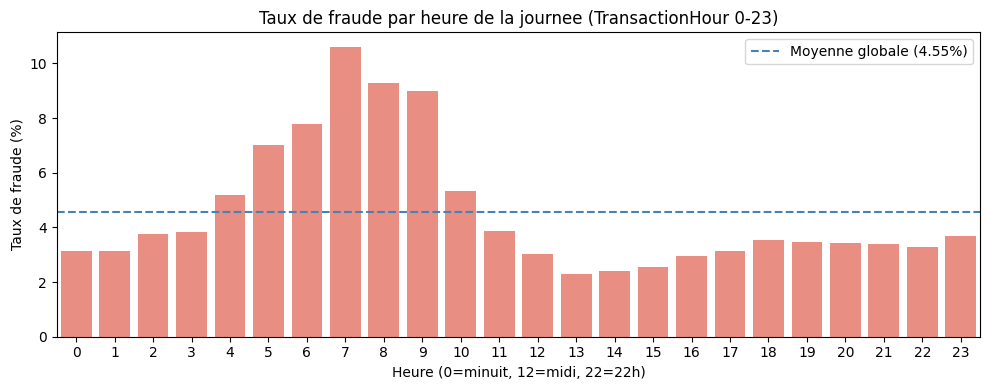

In [ ]:
# --- TransactionHour, is_night_transaction, UID keys pour freq-encoding ---
df = add_temporal_features(df)
df = add_uid_simple(df)
df = add_uid_full(df)

# Taux de fraude par heure de la journee - style meme que le graphe FN recovery
hour_stats_df = (
    df.groupBy("TransactionHour")
    .agg(count("*").alias("count"), avg("isFraud").alias("fraud_rate"))
    .orderBy("TransactionHour")
    .toPandas())
hour_stats_df["fraud_rate_pct"] = hour_stats_df["fraud_rate"] * 100
display(hour_stats_df[["TransactionHour", "count", "fraud_rate_pct"]])

plt.figure(figsize=(10, 4))
sns.barplot(data=hour_stats_df, x="TransactionHour", y="fraud_rate_pct", color="salmon")
plt.axhline(y=hour_stats_df["fraud_rate_pct"].mean(), color="steelblue", linestyle="--", label=f"Moyenne globale ({hour_stats_df['fraud_rate_pct'].mean():.2f}%)")
plt.title("Taux de fraude par heure de la journee (TransactionHour 0-23)")
plt.xlabel("Heure (0=minuit, 12=midi, 22=22h)")
plt.ylabel("Taux de fraude (%)")
plt.legend()
plt.tight_layout()
plt.show()

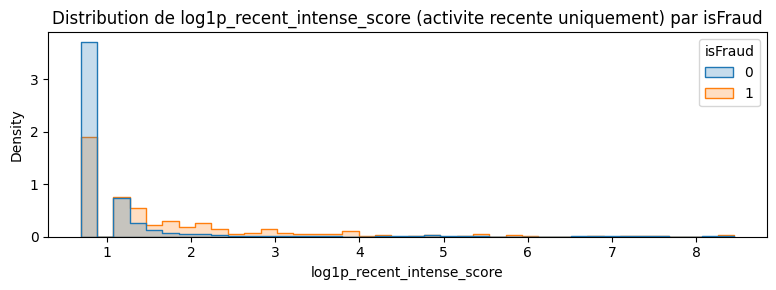

In [ ]:
# Distribution de log1p_recent_intense_score par isFraud (histogramme)
df_sample= df.select("log1p_recent_intense_score", "isFraud").sample(fraction=0.05).toPandas()

plt.figure(figsize=(8, 3))
sns.histplot(
    data=df_sample[df_sample["log1p_recent_intense_score"] > 0],
    x="log1p_recent_intense_score", hue="isFraud",
    bins=40, element="step", stat="density", common_norm=False,)
plt.title("Distribution de log1p_recent_intense_score (activite recente uniquement) par isFraud")
plt.xlabel("log1p_recent_intense_score")
plt.tight_layout()
plt.show()

cleanup(df_sample)


Cardinalite des UIDs :
  uid_simple   =     39,634
  uid_full     =    217,083
  n_total      =    590,540


,uid_full,nb_tx,fraud_rate_pct
0,15775_330.0_-129,1414,0.000000
1,9500_126.0_85,446,0.000000
2,8900_231.0_60,232,0.000000
3,8528_387.0_159,215,0.000000
4,12616_299.0_491,211,17.535545
5,12741_143.0_202,196,0.000000
6,7207_204.0_465,191,0.000000
7,15885_299.0_-22,174,1.149425
8,13597_191.0_48,148,0.000000
9,4121_476.0_8,142,0.000000


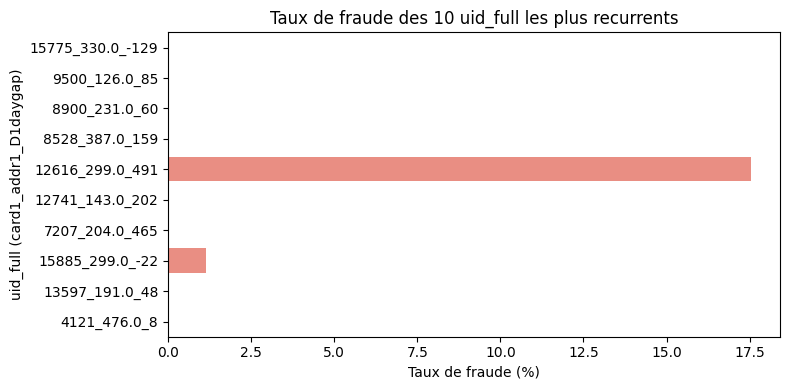

In [ ]:
# Analyse des UIDs : cardinalite globale + top-10 UIDs recurrents vs taux de fraude
uid_cardinality= {
    "uid_simple": df.select("uid_simple").distinct().count(),
    "uid_full":   df.select("uid_full").distinct().count(),
    "n_total":    df.count(),}
print("Cardinalite des UIDs :")
for k, v in uid_cardinality.items():
    print(f"  {k:12s} = {v:>10,}")

# Top 10 uid_full les plus recurrents et leur taux de fraude
top_uids =(
    df.groupBy("uid_full")
    .agg(count("*").alias("nb_tx"), avg("isFraud").alias("fraud_rate"))
    .orderBy(col("nb_tx").desc())
    .limit(10)
    .toPandas())
top_uids["fraud_rate_pct"] = top_uids["fraud_rate"] * 100
display(top_uids[["uid_full", "nb_tx", "fraud_rate_pct"]])

plt.figure(figsize=(8, 4))
sns.barplot(data=top_uids, y="uid_full", x="fraud_rate_pct", color="salmon")
plt.title("Taux de fraude des 10 uid_full les plus recurrents")
plt.xlabel("Taux de fraude (%)")
plt.ylabel("uid_full (card1_addr1_D1daygap)")
plt.tight_layout()
plt.show()


####  Interprétation - profils récurrents et comportement

- **`TransactionHour`** : Conformément à ce qu'on a vu via `is_night_transaction`, l'analyse horaire détaillée confirme les moments charnières. Par exemple, le taux de fraude grimpe fortement à partir de 4h (5.18%), pour battre un record à 7h du matin avec environ **10.61% de fraudes**. Ces pics horaires intenses sur le petit matin justifient complètement l'utilisation des dérivées horaires dans le ML.
- **`log1p_recent_intense_score`** : la version continue capte plus de nuances que le flag binaire `is_recent_intense`, elle sera utile en tant que feature numérique fine pour les arbres.
- **`uid_simple` / `uid_full`** : La cardinalité montre une belle finesse d'identité (plus de **217 000** `uid_full` uniques sur 590 000 transactions). Le top 10 des UIDs fréquents démontre que certains utilisateurs font des **centaines de transactions légitimes** (ex: uid `15775_330.0_-129` fait 1414 de transactions sans fraude). Cependant, à l'inverse, l'UID `12616_299.0_491` a généré 211 transactions avec **17.5% de fraude**. Cet usage abusif d’une seule carte sera capté brillamment par le Frequency Encoding (`uid_full_freq`).

In [ ]:
#df =df.drop( "C1_sur_D1","D1","TransactionAmt")

### Split train / validation avant les transformations 

Le jeu de données est séparé en deux ensembles avant toute transformation nécessitant un apprentissage de statistiques :

* **train_raw** : utilisé pour apprendre les encodeurs, les fréquences, les taux de risque, les paramètres de normalisation et entraîner les modèles ;
* **valid_raw** : réservé à l’évaluation des performances pendant le développement.

Le split est aléatoire, reproductible grâce à `seed=42`, et suit une répartition cible de 80 % pour l’entraînement et 20 % pour la validation.

Cette étape est réalisée avant tout `fit()` afin que les statistiques appliquées à la validation soient calculées uniquement à partir du jeu d’entraînement


In [ ]:
SPLIT_SEED = 42

train_raw, valid_raw = df.randomSplit([0.8, 0.2], seed=SPLIT_SEED)
train_rows = train_raw.count()
valid_rows = valid_raw.count()
print(f"Split anti-leakage préparé dans le notebook 05 | train={train_rows} | valid={valid_rows}")

fraud_stats = (
    train_raw.select("isFraud")
    .agg(
        count("*").alias("total"),
        spark_sum(when(col("isFraud") == 1, 1).otherwise(0)).alias("frauds"),)
    .first())

train_frauds = int(fraud_stats["frauds"] or 0)
train_nonfrauds = int(fraud_stats["total"]) - train_frauds
if train_frauds == 0:
    raise ValueError("Aucune fraude trouvée dans train_raw.")
fraud_weight = train_nonfrauds / train_frauds
print(f"Poids fraude calculé sur train_raw : {fraud_weight:.4f}")

save_json(
    METADATA_DIR / "split_metadata.json",
    {
        "split_seed": SPLIT_SEED,
        "train_rows": int(train_rows),
        "valid_rows": int(valid_rows),
        "fraud_weight": float(fraud_weight),
        "note": "Split effectué avant scaling/encoding pour éviter le leakage.",},)


Split anti-leakage préparé dans le notebook 05 | train=472453 | valid=118087
Poids fraude calculé sur train_raw : 27.5332


In [22]:
for name, data in [("train", train_raw), ("valid", valid_raw), ("global", df)]:
    fraud_rate = data.agg(avg("isFraud").alias("fraud_rate")).first()["fraud_rate"]
    print(f"{name} : taux de fraude = {fraud_rate:.4f}")

train : taux de fraude = 0.0350
valid : taux de fraude = 0.0348
global : taux de fraude = 0.0350


### Interprétation du split

Le split produit **472 453 transactions d’entraînement** et **118 087 transactions de validation**, soit environ 80 % / 20 %.

Le poids de fraude calculé sur `train_raw` est de **27,53**. Cela signifie que, dans le jeu d’entraînement, les transactions légitimes sont environ 27,5 fois plus nombreuses que les transactions frauduleuses.

Ce poids sera use dans les modèles compatibles avec une pondération des classes afin d’accorder davantage d’importance aux erreurs commises sur les fraudes.

Le split étant effectué avant les transformations, les données de validation ne participent pas au calcul des fréquences, moyennes, paramètres de normalisation ou taux de fraude utilisés par le pipeline.

### Variables ciblées `FN recovery` avant le scaling

On ajoute ici un nombre limité de variables conçues pour mieux détecter les fraudes que le modèle baseline avait tendance à rater, sans réactiver les anciennes statistiques de groupe trop larges qui ajoutaient du bruit.

Le pack comprend :

- six indicateurs binaires `is_fn_*` ;
- des statistiques agrégées `risk_*` ;
- des statistiques de montant calculées par groupe.

Les mappings et statistiques sont ajustés uniquement sur `train_raw`, puis appliqués à `valid_raw`.

Un lissage (*smoothing*) est appliqué aux statistiques `risk_*` afin de limiter des taux de fraude instables pour les catégories rares.


In [23]:
train_group_df, valid_group_df, fn_recovery_group_cols, fn_recovery_feature_columns = fit_and_apply_fn_recovery_train_valid(
    train_raw,
    valid_raw,
    stats_root=FN_RECOVERY_DIR,
    smoothing=100.0,)

group_cols = fn_recovery_group_cols
group_feature_columns = fn_recovery_feature_columns

save_json(FEATURES_DIR / "fn_recovery_feature_columns.json", fn_recovery_feature_columns)
save_json(FEATURES_DIR / "group_feature_columns.json", group_feature_columns)
save_json(
    METADATA_DIR / "fn_recovery_metadata.json",
    {
        "group_cols": group_cols,
        "feature_columns": fn_recovery_feature_columns,
        "smoothing": 100.0,
        "fit_scope": "train_raw_only_then_apply_valid",
        "note": "Pack minimal pour remonter les FN : flags ciblés + risk rates lissés.",
    },)
save_json(
    METADATA_DIR / "group_stats_metadata.json",
    {
        "group_cols": group_cols,
        "group_feature_columns": group_feature_columns,
        "value_column": "TransactionAmt",
        "note": "Les anciennes group stats larges restent désactivées. Ce fichier trace le pack FN recovery minimal.",
    },)
print(f"FN recovery features ajoutées : {len(fn_recovery_feature_columns)} colonnes")
print(fn_recovery_feature_columns)

FN recovery features ajoutées : 18 colonnes
['is_fn_productW_unknown_device', 'is_fn_productW_unknown_recipient', 'is_fn_debit_unknown_device', 'is_fn_debit_unknown_recipient', 'is_fn_m4_m0_productW', 'is_fn_unknown_device_unknown_recipient', 'risk_card1_fraud_rate', 'risk_card1_count_log', 'risk_card1_amt_mean', 'risk_card1_amt_std', 'risk_product_card6_fraud_rate', 'risk_product_card6_count_log', 'risk_product_device_fraud_rate', 'risk_product_device_count_log', 'risk_device_r_fraud_rate', 'risk_device_r_count_log', 'risk_amt_over_card1_mean', 'risk_amt_z_card1']


In [24]:
fn_flag_rows = []

for feature in [c for c in fn_recovery_feature_columns if c.startswith("is_fn_")]:
    row = (
        train_group_df
        .filter(col(feature) == 1)
        .agg(
            count("*").alias("count"),
            avg("isFraud").alias("fraud_rate"),
        )
        .first())

    fn_flag_rows.append({
        "feature": feature,
        "count_flag_1": row["count"],
        "fraud_rate_pct": round(row["fraud_rate"] * 100, 2) if row["fraud_rate"] is not None else 0,})

fn_flag_summary_df = pd.DataFrame(fn_flag_rows).sort_values("fraud_rate_pct", ascending=False)
display(fn_flag_summary_df)

,feature,count_flag_1,fraud_rate_pct
4,is_fn_m4_m0_productW,148711,3.25
5,is_fn_unknown_device_unknown_recipient,352038,2.05
0,is_fn_productW_unknown_device,351450,2.04
1,is_fn_productW_unknown_recipient,351450,2.04
2,is_fn_debit_unknown_device,297779,1.64
3,is_fn_debit_unknown_recipient,298494,1.64


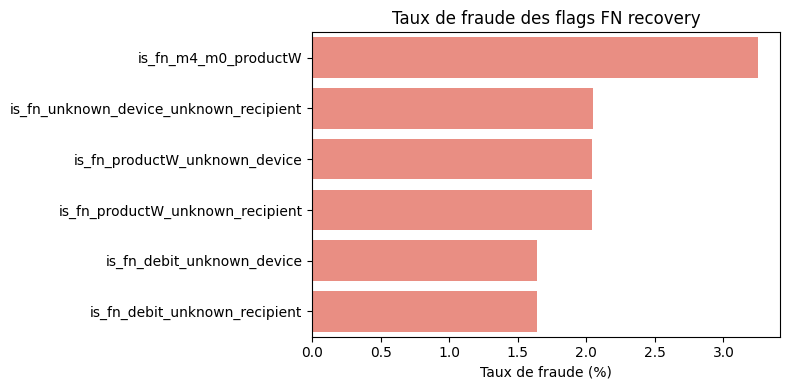

In [25]:
plt.figure(figsize=(8, 4))
sns.barplot(data=fn_flag_summary_df, y="feature", x="fraud_rate_pct", color="salmon")
plt.title("Taux de fraude des flags FN recovery")
plt.xlabel("Taux de fraude (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

###  Mise à l’échelle & Encodage des variables

Objectif : Préparer les variables pour une utilisation efficace avec les modèles de machine learning.

**Pt clé anti-leakage :** le `fit()` du `StandardScaler`, du `StringIndexer`, du `OneHotEncoder`, du `frequency encoding` et du `target encoding` est désormais appris **uniquement sur `train_raw`**, puis appliqué tel quel à `valid_raw`.

#### Standardisation des variables numériques

Certaines variables numériques présentent des échelles très différentes (ex. montants , jours, identifiants, etc.). Cela peut nuire à certains algorithmes sensibles à l’échelle comme la régression logistique, le k-means, ou encore les modèles linéaires.

Pour y remédier, nous appliquons une standardisation (via `StandardScaler`) sur les **variables numériques continues**, c’est-à-dire :

- qui sont de type numérique (`int`, `double`)
- qui possèdent un **nombre suffisant de modalités**
- en excluant les colonnes binaires (`is_`, `has_`, etc.) ou déjà encodées (`OneHot`, `index`)

Le `StandardScaler` transforme chaque variable pour qu’elle ait :
- une **moyenne centrée à 0**
- un **écart-type de 1**

Dans cette version, on garde le pipeline de base avec les vars ciblé  `FN recovery` minimal appris sur train uniquement

In [26]:
train_df, valid_df, scaler_model, cols_to_scale = fit_and_apply_scaler_train_valid(train_group_df, valid_group_df)


In [27]:
scaler_model.write().overwrite().save((SCALING_DIR / "scaler_model").as_posix())
save_json(FEATURES_DIR / "cols_to_scale.json", cols_to_scale)
save_json(
    METADATA_DIR / "scaling_metadata.json",
    {
        "cols_to_scale_count": len(cols_to_scale),
        "cols_to_scale": cols_to_scale,
        "fit_scope": "train_raw_only",
    },)


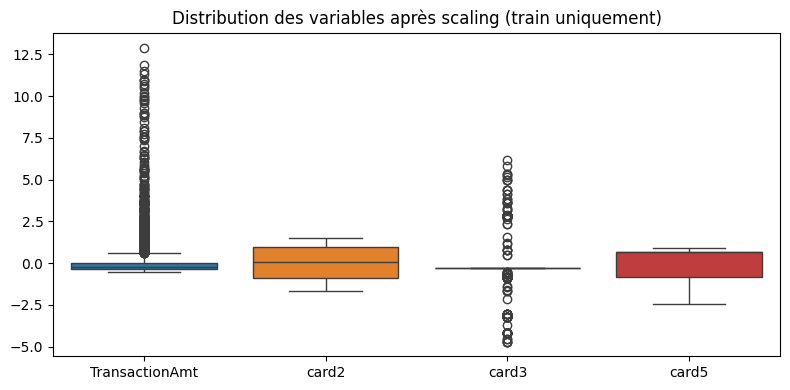

In [28]:
train_df = train_df.withColumn("scaled_array", vector_to_array("scaled_features"))

df_sample = train_df.select("scaled_array").limit(10000).toPandas()
scaled_df = pd.DataFrame(df_sample["scaled_array"].tolist(), columns=cols_to_scale)

plt.figure(figsize=(8, 4))
sns.boxplot(data=scaled_df[cols_to_scale[1:5]])
plt.title("Distribution des variables après scaling (train uniquement)")
plt.tight_layout()
plt.show()
train_df = train_df.drop("scaled_array")
cleanup(df_sample, scaled_df)


### OneHot Encoding des variables catégorielles

Les modèles de machine learning ne peuvent pas exploiter directement les variables catégorielles sous forme de chaînes (`string`). Il est donc nécessaire de les encoder en variables numériques.

Nous utilisons ici un **OneHot Encoding**, qui transforme chaque modalité en une colonne binaire (`0` ou `1`). Cela permet de :

- préserver l'information sans introduire de hiérarchie arbitraire (contrairement au `StringIndexer` seul)
- éviter que le modèle interprète un ordre entre les catégories

####  Étapes de l'encodage

1. **Sélection des variables catégorielles** :
    - détecter les colonnes de type `string` 
    - conservation uniquement des variables :
        - à **signal significatif** (fort écart de taux de fraude)
        - à **modalité raisonnable**
    - exclusion manuelle des colonnes :
        - à **forte cardinalité (> 100 modalités)** → explosion dimensionnelle
        - à **faible pouvoir discriminant** (écart de taux de fraude faible)

2. **Encodage** :
   - `StringIndexer`: pour convertir les chaînes en indices numériques
   - `OneHotEncoder`: pour transformer ces indices en vecteurs binaires


In [29]:
df_types = spark.createDataFrame(train_df.dtypes, ["column", "type"])
df_types.groupBy("type").count().orderBy("count", ascending=False).show()

# liste des colonnes catégorielle
cat_cols = [c for c, t in train_df.dtypes if t == "string"]


+------+-----+
|  type|count|
+------+-----+
|double|  410|
|   int|   84|
|string|   35|
|vector|    2|
+------+-----+



In [30]:
total_rows = train_df.count()
results = []

for var in cat_cols:
    try:
        stats_df = (
            train_df.groupBy(var)
              .agg(
                  count("*").alias("cnt"),
                  spark_round(avg("isFraud") * 100, 2).alias("fraud_rate")))

        stats = stats_df.agg(
            spark_round(expr(f"max(cnt) / {total_rows} * 100"), 2).alias("max_freq"),
            expr("min(fraud_rate)").alias("min_fraud"),
            expr("max(fraud_rate)").alias("max_fraud")).first()

        n_modalites = train_df.select(var).distinct().count()

        results.append({
            "variable": var,
            "n_modalites": n_modalites,
            "max_freq_%": stats["max_freq"],
            "fraude_min_%": stats["min_fraud"],
            "fraude_max_%": stats["max_fraud"]
            })
    except Exception as e:
        print(f"Erreur {var}: {e}")

df_cat_analysis = pd.DataFrame(results).sort_values("n_modalites", ascending=False)
df_cat_analysis.head(30)


,variable,n_modalites,max_freq_%,fraude_min_%,fraude_max_%
34,uid_full,190733,0.24,0.00,100.00
33,uid_simple,36273,1.70,0.00,100.00
32,card_id,13927,2.37,0.00,100.00
24,id_33,248,87.59,0.00,100.00
0,risk_key_device_r,170,74.51,0.00,100.00
23,id_31,128,76.18,0.00,100.00
22,id_30,76,86.86,0.00,50.00
7,R_emaildomain,61,76.70,0.00,93.94
6,P_emaildomain,60,38.67,0.00,37.70
2,risk_key_product_card6,18,62.19,0.00,17.04


In [31]:
train_df = add_m789_combo(train_df)
valid_df = add_m789_combo(valid_df)


In [32]:
cols_to_remove = [ 
    "id_30", "id_31", "id_33",  # Haute cardinalité
    "M7", "M8", "M9" ]           # Faible signal 

#### Sélection des variables catégorielles à encoder

L’analyse croisée de la **cardinalité des modalités** et de leur **pouvoir discriminant** (écart de taux de fraude entre les modalités) permet d’identifier les variables catégorielles les plus utiles.

**Variables retenues pour encodage (`OneHotEncoding`)** :
- `ProductCD`, `card4`, `card6` : types de produits et réseaux bancaires
- `P_emaildomain`, `R_emaildomain` : domaine d’email utilisateur (signal fort)
- `DeviceType`, `M4` : caractéristiques comportementales
- `card4_card6` : combinaison créée, informative
- `id_15`, `id_16`, `id_28`, `id_29`, `id_35`, `id_36`, `id_37`, `id_38` : variables d'identité à faible cardinalité avec signal intéressant

**Variables exclues** :
- `id_30`, `id_31`, `id_33` : trop grande cardinalité (> 100 modalités), risque de **sur-apprentissage**
- `M7`, `M8`, `M9` : peu de différenciation en termes de fraude, **signal faible**

**Variables en attente d’évaluation** :
- `M1`, `M2`,`M6`... etc. seront réévaluées lors de la **sélection de features** (via LightGBM, SHAP)

Cette sélection permet de **réduire la complexité**, d’**améliorer la lisibilité** du modèle et de garantir une **meilleure performance générale**.

### Encodage des variables catégorielles retenues

In [33]:
vars_to_encode = VARS_TO_ENCODE


In [34]:
train_df, valid_df, encoding_pipeline_model = fit_and_apply_encoding_train_valid(
    train_df,
    valid_df,
    vars_to_encode=vars_to_encode,)


In [35]:
encoding_pipeline_model.write().overwrite().save((ENCODING_DIR / "onehot_pipeline_model").as_posix())
save_json(FEATURES_DIR / "vars_to_encode.json", vars_to_encode)
save_json(
    METADATA_DIR / "encoding_metadata.json",
    {
        "vars_to_encode_count": len(vars_to_encode),
        "vars_to_encode": vars_to_encode,
        "fit_scope": "train_raw_only",
    },
)


#### Frequency encoding 

In [36]:
train_df, valid_df, frequency_columns = fit_and_apply_frequency_train_valid(
    train_df,
    valid_df,
    FREQUENCY_ENCODING_DIR,
    columns=VARS_TO_FREQUENCY_ENCODE,
)
save_json(FEATURES_DIR / "frequency_columns.json", frequency_columns)


Frequency encoding optimisé : matérialisation source étroite pour 8 colonnes
Frequency encoding : P_emaildomain
Frequency encoding : R_emaildomain
Frequency encoding : card4_card6
Frequency encoding : M789_combo
Frequency encoding : id_30
Frequency encoding : id_31
Frequency encoding : uid_simple
Frequency encoding : uid_full


#### Target Encoding 

In [ ]:
# train_df, valid_df, target_fill_values, target_columns = fit_and_apply_target_train_valid(
#     train_df,
#     valid_df,
#     TARGET_ENCODING_DIR,
#     columns=VARS_TO_TARGET_ENCODE,
#     target_col="isFraud",)
#save_json(FEATURES_DIR / "target_columns.json", target_columns)
# save_json(METADATA_DIR / "target_encoding_fill_values.json", target_fill_values)

target_columns = []
target_fill_values = {}
save_json(FEATURES_DIR / "target_columns.json", target_columns)
save_json(METADATA_DIR / "target_encoding_fill_values.json", target_fill_values)


In [38]:
encoded_cols = [f"{col}_vec" for col in vars_to_encode]

train_df.select(encoded_cols).printSchema()


root
 |-- ProductCD_vec: vector (nullable = true)
 |-- card4_vec: vector (nullable = true)
 |-- card6_vec: vector (nullable = true)
 |-- DeviceType_vec: vector (nullable = true)
 |-- M4_vec: vector (nullable = true)
 |-- id_15_vec: vector (nullable = true)
 |-- id_16_vec: vector (nullable = true)
 |-- id_28_vec: vector (nullable = true)
 |-- id_29_vec: vector (nullable = true)
 |-- id_35_vec: vector (nullable = true)
 |-- id_36_vec: vector (nullable = true)
 |-- id_37_vec: vector (nullable = true)
 |-- id_38_vec: vector (nullable = true)
 |-- M1_vec: vector (nullable = true)
 |-- M2_vec: vector (nullable = true)
 |-- M3_vec: vector (nullable = true)
 |-- M5_vec: vector (nullable = true)
 |-- M6_vec: vector (nullable = true)
 |-- id_12_vec: vector (nullable = true)
 |-- id_34_vec: vector (nullable = true)



#### Interprétation - Encodage des variables catégorielles 

Les variables catégorielles sélectionnées (`ProductCD`, `card4`, `id_38`, etc.) ont été encodées via un **pipeline Spark** combinant :

- `StringIndexer` → convertit les modalités en indices numériques.
- `OneHotEncoder` → transforme ces indices en vecteurs binaires (`xxx_vec`).

 Exemple : `card6 == "credit"` devient un vecteur sparse `(5,[1],[1.0])`.

Les colonnes d’origine (`string`) sont supprimées après transformation pour ne conserver que les vecteurs encodés.

Résultat :
- Un ensemble de colonnes numériques `xxx_vec` prêtes pour la modélisation.
- Structure adaptée aux modèles linéaires, arbres, ou réseaux de neurones.

## 6.3 Finalisation du dataset

####  Objectif : Obtenir un jeu de données complet, propre et entièrement numérique, prêt pour la modélisation

Cette étape consiste à assembler toutes les features finales dans un vecteur unique et à supprimer les colonnes obsolètes ou redondantes.


In [39]:
final_features = get_baseline_feature_columns(train_df)
train_df, valid_df, final_features = assemble_train_valid_features(train_df, valid_df, final_features=final_features)
train_df.select("features", "isFraud").show(3, truncate=20)


+--------------------+-------+
|            features|isFraud|
+--------------------+-------+
|[0.0,0.0,0.0,0.0,...|      0|
|[0.0,0.0,0.0,0.0,...|      0|
|[1.0,1.0,1.0,1.0,...|      0|
+--------------------+-------+
only showing top 3 rows



In [ ]:
save_json(FEATURES_DIR / "baseline_features.json", final_features)
save_json(
    METADATA_DIR / "feature_engineering_profile.json",
    {
        "train_profile": dataframe_profile(train_df),
        "valid_profile": dataframe_profile(valid_df),
        "feature_count": len(final_features),
        "frequency_columns_count": len(frequency_columns),
        "group_feature_columns_count": len(group_feature_columns),
        "fit_scope": "train_only_then_apply_valid",
    },)

In [41]:
train_df = train_df.withColumn("classWeight", when(col("isFraud") == 1, fraud_weight).otherwise(1.0))
valid_df = valid_df.withColumn("classWeight", when(col("isFraud") == 1, fraud_weight).otherwise(1.0))

train_output_path = (STAGE_DATA_DIR / "train_features_train_split.parquet").as_posix()
valid_output_path = (STAGE_DATA_DIR / "train_features_valid_split.parquet").as_posix()
full_output_path = (STAGE_DATA_DIR / "train_features_full.parquet").as_posix()

simple_train_output_path = (STAGE_DATA_DIR / "train_features_simple_train_split.parquet").as_posix()
simple_valid_output_path = (STAGE_DATA_DIR / "train_features_simple_valid_split.parquet").as_posix()
simple_full_output_path = (STAGE_DATA_DIR / "train_features_simple.parquet").as_posix()

print(f"classWeight fraude réutilisé depuis train_raw : {fraud_weight:.4f}")


classWeight fraude réutilisé depuis train_raw : 27.5332


In [42]:
print("Sauvegarde du split train...")
train_df.repartition(4).write.mode("overwrite").parquet(train_output_path)

print("Sauvegarde du split valid...")
valid_df.repartition(4).write.mode("overwrite").parquet(valid_output_path)

print("Reconstruction du full dataset depuis les parquets sauvegardés...")
saved_train_df = spark.read.parquet(train_output_path)
saved_valid_df = spark.read.parquet(valid_output_path)
df_final = saved_train_df.unionByName(saved_valid_df)
df_final.write.mode("overwrite").parquet(full_output_path)


Sauvegarde du split train...
Sauvegarde du split valid...
Reconstruction du full dataset depuis les parquets sauvegardés...


In [43]:
train_df_clean = train_df.select("features", "isFraud", "classWeight")
valid_df_clean = valid_df.select("features", "isFraud", "classWeight")

print("Sauvegarde des versions simplifiées...")
train_df_clean.repartition(4).write.mode("overwrite").parquet(simple_train_output_path)
valid_df_clean.repartition(4).write.mode("overwrite").parquet(simple_valid_output_path)

saved_train_clean = spark.read.parquet(simple_train_output_path)
saved_valid_clean = spark.read.parquet(simple_valid_output_path)
df_final_clean = saved_train_clean.unionByName(saved_valid_clean)
df_final_clean.write.mode("overwrite").parquet(simple_full_output_path)

mlflow.log_params(
    {
        "cols_to_scale_count": len(cols_to_scale),
        "vars_to_encode_count": len(vars_to_encode),
        "frequency_columns_count": len(frequency_columns),
        "group_feature_columns_count": len(group_feature_columns),
        "final_feature_count": len(final_features),
        "split_seed": SPLIT_SEED,
        "fit_scope": "train_only_then_apply_valid",
        "fraud_weight": float(fraud_weight),
    })

train_profile = {"rows": int(train_rows), "columns": len(train_df.columns)}
valid_profile = {"rows": int(valid_rows), "columns": len(valid_df.columns)}
mlflow.log_metrics(
    {
        "train_rows": train_profile["rows"],
        "train_columns": train_profile["columns"],
        "valid_rows": valid_profile["rows"],
        "valid_columns": valid_profile["columns"],
        "weighted_rows_total": float(train_rows + valid_rows),
    })

mlflow.log_artifacts(STAGE_ARTIFACTS_DIR.as_posix(), artifact_path=STAGE_NAME)
mlflow.end_run()
print(f"Artifacts sauvegardés dans {STAGE_ARTIFACTS_DIR}")
print(f"Données sauvegardées dans {STAGE_DATA_DIR}")


Sauvegarde des versions simplifiées...
Artifacts sauvegardés dans C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\05_feature_engineering
Données sauvegardées dans C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\05_feature_engineering\data


In [44]:
# --- Vérif ---
with open(FEATURES_DIR / "baseline_features.json", "r") as f:
    toutes_les_variables_sauvegardees = json.load(f)

print(f" {len(toutes_les_variables_sauvegardees)}")
pprint(toutes_les_variables_sauvegardees, compact=True)


 126
['has_identity', 'has_D6', 'has_D8', 'has_D9', 'has_D12', 'has_D13', 'has_D14',
 'has_V138', 'has_V139', 'has_V140', 'has_V141', 'has_V142', 'has_V143',
 'has_V144', 'has_V145', 'has_V146', 'has_V147', 'has_V148', 'has_V149',
 'has_V150', 'has_V151', 'has_V152', 'has_V153', 'has_V154', 'has_V155',
 'has_V156', 'has_V157', 'has_V158', 'has_V159', 'has_V160', 'has_V161',
 'has_V162', 'has_V163', 'has_V164', 'has_V165', 'has_V166', 'has_V322',
 'has_V323', 'has_V324', 'has_V325', 'has_V326', 'has_V327', 'has_V328',
 'has_V329', 'has_V330', 'has_V331', 'has_V332', 'has_V333', 'has_V334',
 'has_V335', 'has_V336', 'has_V337', 'has_V338', 'has_V339', 'has_id_03',
 'has_id_04', 'has_id_09', 'has_id_10', 'has_id_14', 'has_id_32', 'has_id_33',
 'has_id_34', 'is_recent_activity', 'is_high_amount', 'is_product_C',
 'is_credit_card', 'is_discover_card', 'is_weekend', 'log1p_TransactionAmt',
 'log1p_C1_sur_D1', 'log1p_D1', 'is_email_mismatch', 'log1p_D15',
 'log1p_Amt_sur_D15', 'is_missing_D15'